In [2]:
import pandas as pd

In [8]:
# Load dataset
df = pd.read_excel(r"C:\Users\Lenovo\Downloads\Data Analytics (DM)\customer.xlsx", sheet_name='customer')

In [6]:
!pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]




[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
# Check structure and missing values
print("--- Dataset Info ---")
print(df.info())
print("\n--- Missing Values Audit ---")
print(df.isnull().sum())

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   invoice_no      1000 non-null   str           
 1   customer_id     1000 non-null   str           
 2   gender          1000 non-null   str           
 3   age             1000 non-null   int64         
 4   category        1000 non-null   str           
 5   quantity        1000 non-null   int64         
 6   price           1000 non-null   float64       
 7   payment_method  1000 non-null   str           
 8   invoice_date    1000 non-null   datetime64[us]
 9   shopping_mall   1000 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(2), str(6)
memory usage: 78.3 KB
None

--- Missing Values Audit ---
invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment

In [10]:
# Feature Engineering: Total Revenue and Age Groups
df['total_revenue'] = df['quantity'] * df['price']

def categorize_age(age):
    if 18 <= age <= 30:
        return '18-30 (Young Adults)'
    elif 31 <= age <= 50:
        return '31-50 (Middle-Aged)'
    elif 51 <= age <= 70:
        return '51-70 (Seniors)'
    else:
        return 'Other'

df['age_group'] = df['age'].apply(categorize_age)
print("\nData successfully prepared with Total Revenue and Age Groups!")


Data successfully prepared with Total Revenue and Age Groups!


In [11]:
# Gender Summary
gender_summary = df.groupby('gender').agg(
    total_transactions=('invoice_no', 'count'),
    total_quantity=('quantity', 'sum'),
    total_revenue=('total_revenue', 'sum')
).reset_index()

print("=== GENDER SUMMARY ===")
print(gender_summary)

=== GENDER SUMMARY ===
   gender  total_transactions  total_quantity  total_revenue
0  Female                 620            1853     1408881.11
1    Male                 380            1128      956486.66


In [12]:
# Age Group Summary
age_summary = df.groupby('age_group').agg(
    total_transactions=('invoice_no', 'count'),
    total_quantity=('quantity', 'sum'),
    total_revenue=('total_revenue', 'sum')
).reset_index()

print("\n=== AGE GROUP SUMMARY ===")
print(age_summary)


=== AGE GROUP SUMMARY ===
              age_group  total_transactions  total_quantity  total_revenue
0  18-30 (Young Adults)                 253             781      569273.18
1   31-50 (Middle-Aged)                 380            1143      894647.76
2       51-70 (Seniors)                 367            1057      901446.83


In [13]:
# Payment Method Summary
payment_summary = df.groupby('payment_method').agg(
    total_transactions=('invoice_no', 'count'),
    total_revenue=('total_revenue', 'sum')
).reset_index()

print("=== PAYMENT METHOD SUMMARY ===")
print(payment_summary)

=== PAYMENT METHOD SUMMARY ===
  payment_method  total_transactions  total_revenue
0           Cash                 420     1041239.48
1    Credit Card                 366      770272.60
2     Debit Card                 214      553855.69


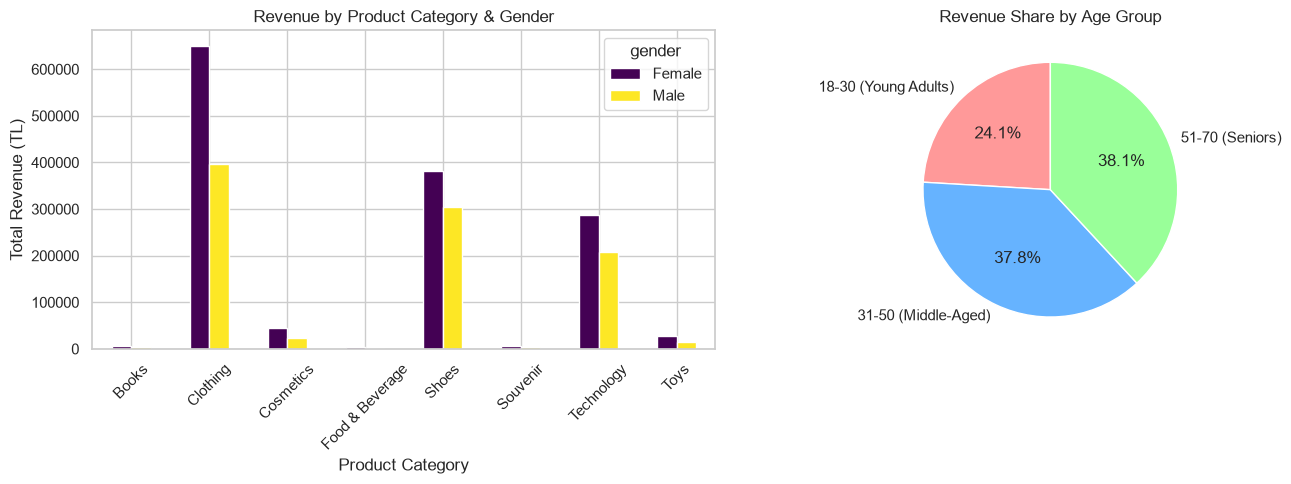

The charts are generated


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# Chart 1: Revenue by Gender & Category
plt.subplot(1, 2, 1)
cat_gender = df.groupby(['category', 'gender'])['total_revenue'].sum().unstack()
cat_gender.plot(kind='bar', ax=plt.gca(), colormap='viridis')
plt.title('Revenue by Product Category & Gender')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue (TL)')
plt.xticks(rotation=45)

# Chart 2: Revenue by Age Group
plt.subplot(1, 2, 2)
age_rev = df.groupby('age_group')['total_revenue'].sum()
age_rev.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff','#99ff99'])
plt.title('Revenue Share by Age Group')
plt.ylabel('')

plt.tight_layout()
plt.savefig('project_charts.png', dpi=300)
plt.show()
print("The charts are generated")

In [17]:
df['total_revenue'] = df['quantity'] * df['price']
df['invoice_date'] = pd.to_datetime(df['invoice_date'])

# 1. Total Sales and Revenue by Category
category_performance = df.groupby('category').agg(
    total_units_sold=('quantity', 'sum'),
    total_revenue_tl=('total_revenue', 'sum'),
    transaction_count=('invoice_no', 'count')
).sort_values(by='total_units_sold', ascending=False)

print("=== CATEGORY PERFORMANCE SUMMARY ===")
print(category_performance)

# 2. Monthly Demand Trend for Categories
df['month'] = df['invoice_date'].dt.month_name()
monthly_demand = df.groupby(['month', 'category'])['quantity'].sum().unstack(fill_value=0)
print("\n=== MONTHLY DEMAND TREND ===")
print(monthly_demand[['Clothing', 'Shoes', 'Cosmetics', 'Technology']])

=== CATEGORY PERFORMANCE SUMMARY ===
                 total_units_sold  total_revenue_tl  transaction_count
category                                                              
Clothing                      977        1048179.44                338
Cosmetics                     473          69081.34                155
Food & Beverage               358           6715.32                125
Toys                          324          42362.88                104
Shoes                         312         685394.14                103
Souvenir                      213           9559.95                 66
Books                         196          10574.70                 67
Technology                    128         493500.00                 42

=== MONTHLY DEMAND TREND ===
category   Clothing  Shoes  Cosmetics  Technology
month                                            
April            53     50         38           7
August          104     11         47          16
December         53    